# Task 2: California Housing Price Prediction (Ridge & Lasso Regression)
**Curriculum Reference:** DT-2026-NKPSG  
**Focus:** Continuous Regression Modeling, Feature Engineering, Regularization & Residual Analysis  

---

## 1. Objective & Mathematical Formulations
Predict continuous median house values (`median_house_value`) using the California Housing dataset. This benchmark analyzes the impact of feature engineering and regularized linear models against standard Ordinary Least Squares (OLS).

### Loss Functions
- **Ordinary Least Squares (OLS):**
  $$\mathcal{L}_{\text{OLS}}(\mathbf{w}) = \frac{1}{2n} \sum_{i=1}^n \left( y_i - \mathbf{w}^T \mathbf{x}_i \right)^2$$

- **Ridge Regression (L2 Regularization):**
  Penalizes large weights to mitigate multicollinearity and reduce variance:
  $$\mathcal{L}_{\text{Ridge}}(\mathbf{w}) = \mathcal{L}_{\text{OLS}}(\mathbf{w}) + \alpha \sum_{j=1}^p w_j^2$$

- **Lasso Regression (L1 Regularization):**
  Drives uninformative feature coefficients to zero, performing intrinsic feature selection:
  $$\mathcal{L}_{\text{Lasso}}(\mathbf{w}) = \mathcal{L}_{\text{OLS}}(\mathbf{w}) + \alpha \sum_{j=1}^p |w_j|$$


## 2. Setup & Imports

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120


## 3. Data Ingestion & Missing Value Analysis

In [2]:
data_path = os.path.join("..", "data", "housing.csv")
df = pd.read_csv(data_path)

print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
print("\nMissing value count per column:")
missing = df.isnull().sum()
print(missing[missing > 0])
df.head(5)


Dataset Dimensions: 20640 rows, 10 columns

Missing value count per column:
total_bedrooms    207
dtype: int64


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 4. Feature Engineering & Median Imputation
1. **Median Imputation:** Fill missing values in `total_bedrooms` using the median strategy.
2. **Interaction Ratios:**
   - `rooms_per_household = total_rooms / households`
   - `bedrooms_per_room = total_bedrooms / total_rooms`
   - `population_per_household = population / households`


In [3]:
# Impute missing total_bedrooms
imputer = SimpleImputer(strategy="median")
df["total_bedrooms"] = imputer.fit_transform(df[["total_bedrooms"]])

# Interaction features
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]
df["population_per_household"] = df["population"] / df["households"]

print("Engineered features created. Null count remaining:", df.isnull().sum().sum())
df[["rooms_per_household", "bedrooms_per_room", "population_per_household"]].describe().T


Engineered features created. Null count remaining: 0


,count,mean,std,min,25%,50%,75%,max
rooms_per_household,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
bedrooms_per_room,20640.0,0.213794,0.065248,0.037151,0.175225,0.203159,0.240126,2.824675
population_per_household,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333


## 5. Feature Correlation Heatmap

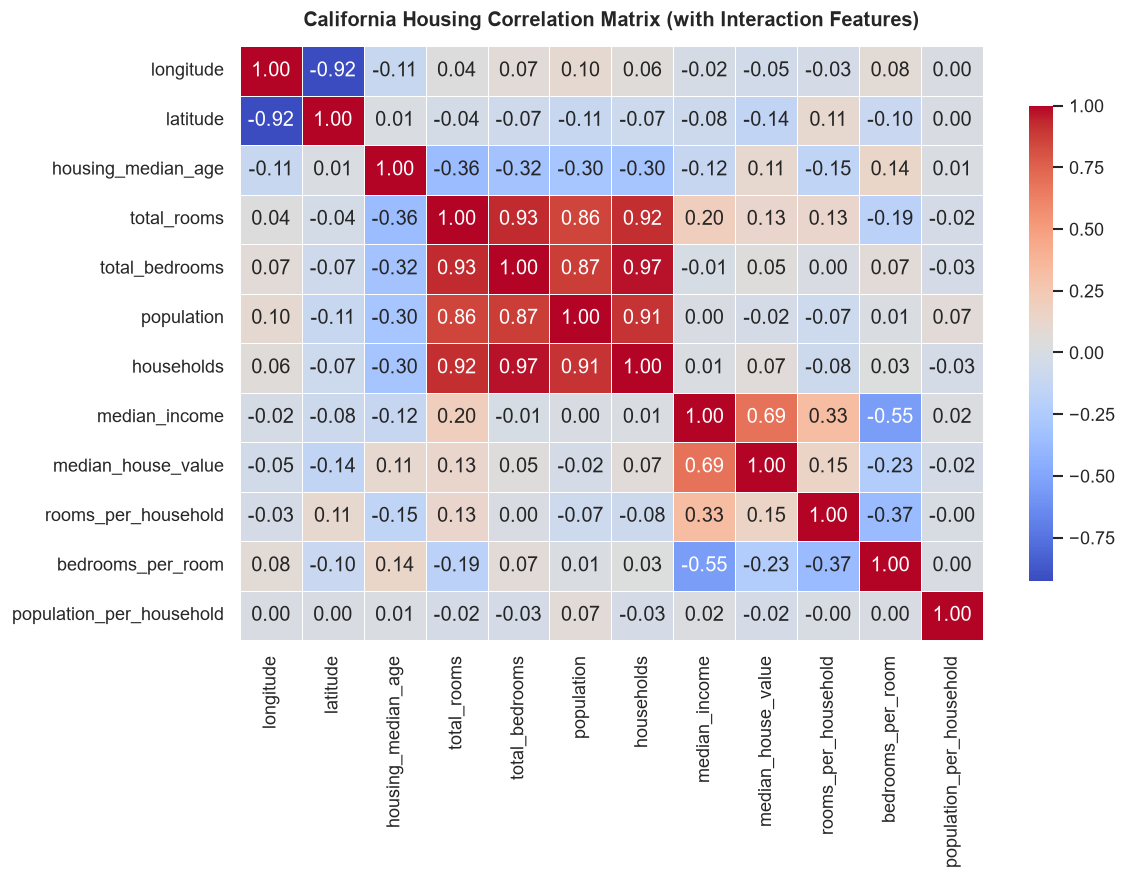

In [4]:
plt.figure(figsize=(10, 7.5))
numeric_df = df.select_dtypes(include=[np.number])
corr = numeric_df.corr()

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("California Housing Correlation Matrix (with Interaction Features)", fontsize=12, weight="bold", pad=12)
plt.tight_layout()
plt.show()


## 6. Encoding & Preprocessing
- One-hot encode the categorical column `ocean_proximity`.
- 80/20 train/test split with `random_state=42`.
- Scale all predictor variables with `StandardScaler`.


In [5]:
target_col = "median_house_value"
cat_col = "ocean_proximity"

X_raw = df.drop(columns=[target_col])
y = df[target_col].values

# One-hot encoding
ohe = OneHotEncoder(drop="first", sparse_output=False)
cat_encoded = ohe.fit_transform(X_raw[[cat_col]])
cat_names = [f"ocean_{c}" for c in ohe.get_feature_names_out([cat_col])]

num_cols = [c for c in X_raw.columns if c != cat_col]
X_num = X_raw[num_cols].values

X_combined = np.hstack([X_num, cat_encoded])
feature_names = num_cols + cat_names

# 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X_combined, y, test_size=0.20, random_state=42
)

# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train samples: {X_train_scaled.shape[0]}, Features: {X_train_scaled.shape[1]}")
print(f"Test samples:  {X_test_scaled.shape[0]}")


Train samples: 16512, Features: 15
Test samples:  4128


## 7. Model Training & Hyperparameter Tuning
Train baseline OLS and tune regularization strength ($\alpha$) using 5-fold cross-validation (`GridSearchCV`).


In [6]:
alphas = [0.01, 0.1, 1.0, 10.0, 100.0, 500.0, 1000.0]

# 1. OLS Baseline
ols = LinearRegression()
ols.fit(X_train_scaled, y_train)

# 2. Ridge (L2) with GridSearchCV
ridge_cv = GridSearchCV(
    Ridge(),
    param_grid={"alpha": alphas},
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
)
ridge_cv.fit(X_train_scaled, y_train)
best_ridge = ridge_cv.best_estimator_

# 3. Lasso (L1) with GridSearchCV
lasso_cv = GridSearchCV(
    Lasso(max_iter=5000, random_state=42),
    param_grid={"alpha": alphas},
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1,
)
lasso_cv.fit(X_train_scaled, y_train)
best_lasso = lasso_cv.best_estimator_

print("Optimal Ridge Alpha:", ridge_cv.best_params_["alpha"])
print("Optimal Lasso Alpha:", lasso_cv.best_params_["alpha"])


Optimal Ridge Alpha: 10.0
Optimal Lasso Alpha: 100.0


## 8. Model Evaluation & Benchmark Summary

In [7]:
models = {
    "OLS Linear Regression": ols,
    f"Ridge Regression (alpha={ridge_cv.best_params_['alpha']})": best_ridge,
    f"Lasso Regression (alpha={lasso_cv.best_params_['alpha']})": best_lasso,
}

results = {}
summary_rows = []

for name, model in models.items():
    y_pred = model.predict(X_test_scaled)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results[name] = {"RMSE": rmse, "MAE": mae, "R2": r2, "y_pred": y_pred}
    summary_rows.append({
        "Model": name,
        "RMSE ($)": f"{rmse:,.2f}",
        "MAE ($)": f"{mae:,.2f}",
        "R2 Score": f"{r2:.4f}",
    })

summary_table = pd.DataFrame(summary_rows)
display(summary_table)


,Model,RMSE ($),MAE ($),R2 Score
0,OLS Linear Regression,"72,668.54","50,888.66",0.5970
1,Ridge Regression (alpha=10.0),"72,647.55","50,885.56",0.5973
2,Lasso Regression (alpha=100.0),"72,522.08","50,832.25",0.5986


## 9. Predicted vs Actual Value Scatter Plots

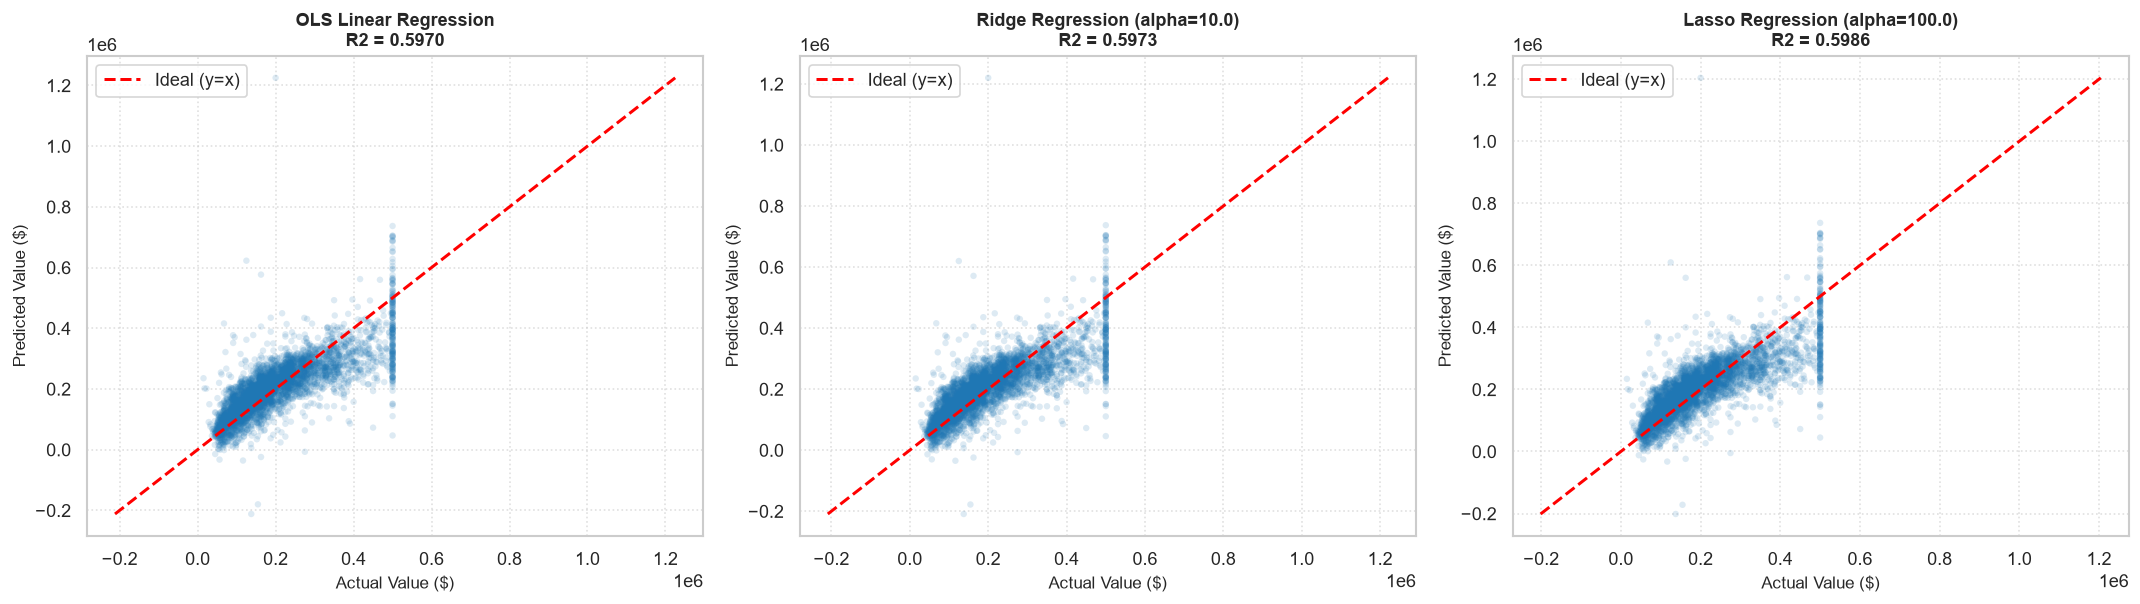

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

for ax, (name, metrics) in zip(axes, results.items()):
    y_pred = metrics["y_pred"]
    ax.scatter(y_test, y_pred, alpha=0.15, s=15, color="#1f77b4", edgecolor="none")
    
    min_v = min(y_test.min(), y_pred.min())
    max_v = max(y_test.max(), y_pred.max())
    ax.plot([min_v, max_v], [min_v, max_v], color="red", linestyle="--", linewidth=1.8, label="Ideal (y=x)")
    
    ax.set_title(f"{name}\nR2 = {metrics['R2']:.4f}", fontsize=11, weight="bold")
    ax.set_xlabel("Actual Value ($)", fontsize=10)
    ax.set_ylabel("Predicted Value ($)", fontsize=10)
    ax.legend(loc="upper left")
    ax.grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


## 10. Residual Error Analysis

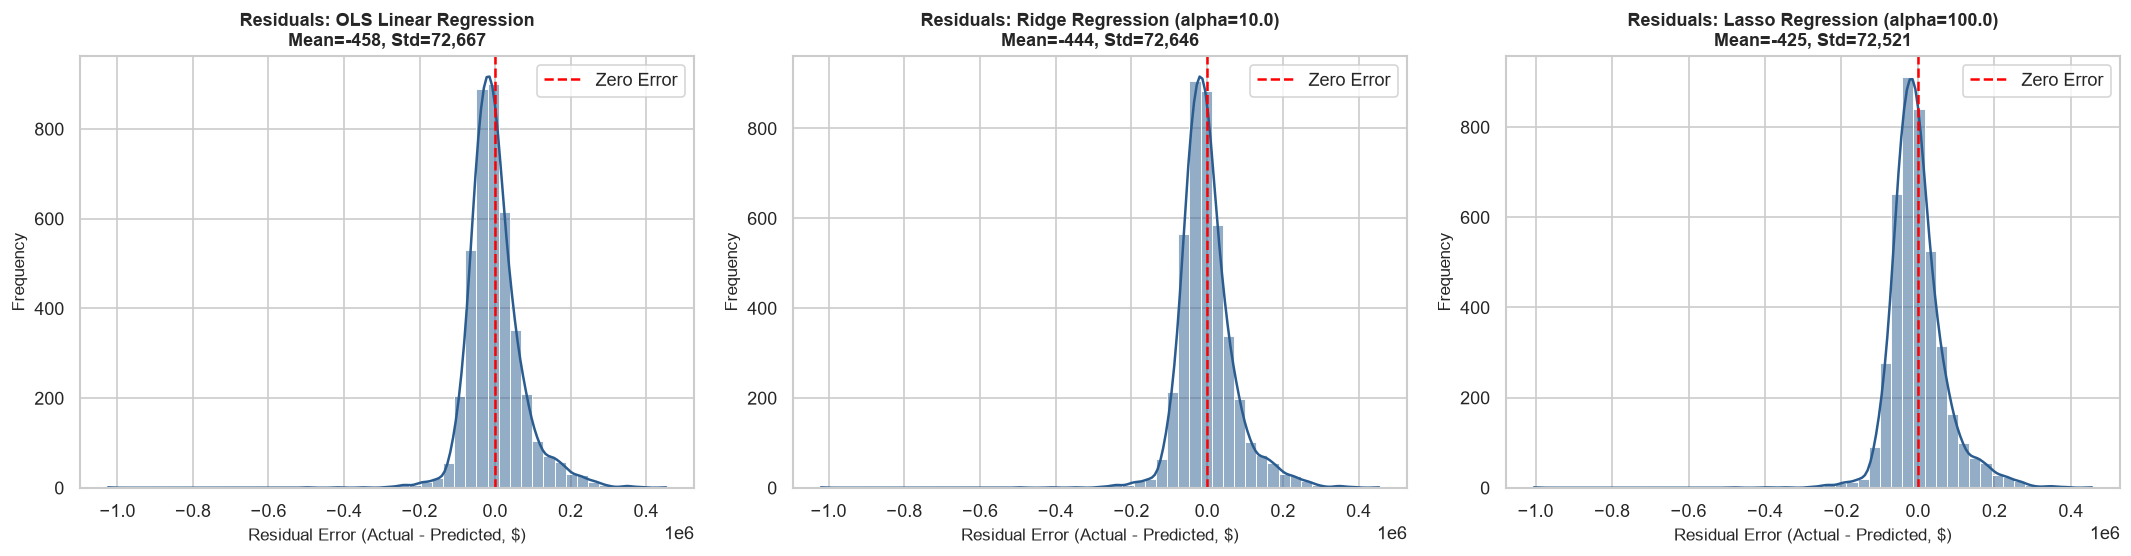

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

for ax, (name, metrics) in zip(axes, results.items()):
    residuals = y_test - metrics["y_pred"]
    sns.histplot(residuals, kde=True, ax=ax, color="#2b5c8f", bins=50)
    
    ax.axvline(0, color="red", linestyle="--", linewidth=1.5, label="Zero Error")
    ax.set_title(f"Residuals: {name}\nMean={np.mean(residuals):,.0f}, Std={np.std(residuals):,.0f}", fontsize=11, weight="bold")
    ax.set_xlabel("Residual Error (Actual - Predicted, $)", fontsize=10)
    ax.set_ylabel("Frequency", fontsize=10)
    ax.legend(loc="upper right")

plt.tight_layout()
plt.show()


## 11. Regularization Coefficient Shrinkage Comparison
Comparison of learned feature weights across OLS, Ridge (L2 shrinkage), and Lasso (L1 sparsity).


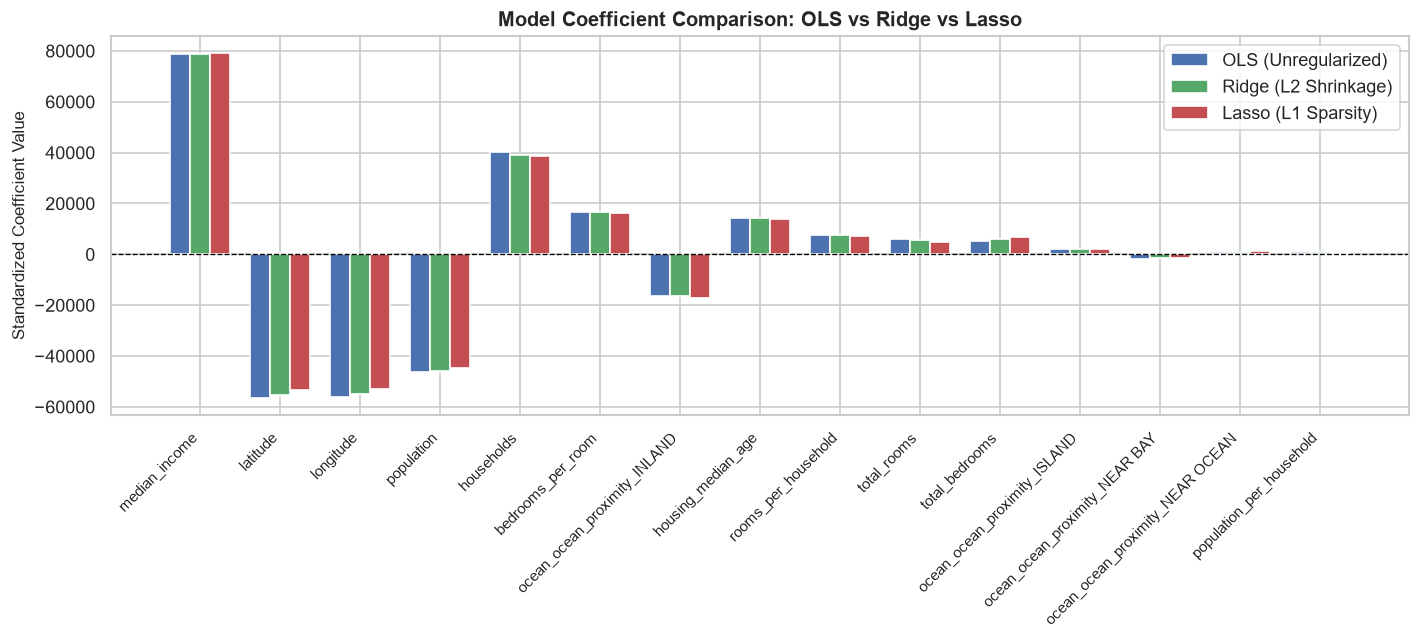

In [10]:
coef_df = pd.DataFrame({
    "Feature": feature_names,
    "OLS": ols.coef_,
    "Ridge": best_ridge.coef_,
    "Lasso": best_lasso.coef_,
}).sort_values(by="OLS", key=abs, ascending=False)

plt.figure(figsize=(12, 5.5))
x = np.arange(len(feature_names))
width = 0.25

plt.bar(x - width, coef_df["OLS"], width=width, label="OLS (Unregularized)", color="#4c72b0")
plt.bar(x, coef_df["Ridge"], width=width, label="Ridge (L2 Shrinkage)", color="#55a868")
plt.bar(x + width, coef_df["Lasso"], width=width, label="Lasso (L1 Sparsity)", color="#c44e52")

plt.axhline(0, color="black", linestyle="--", linewidth=0.8)
plt.xticks(x, coef_df["Feature"], rotation=45, ha="right", fontsize=9)
plt.ylabel("Standardized Coefficient Value", fontsize=10)
plt.title("Model Coefficient Comparison: OLS vs Ridge vs Lasso", fontsize=12, weight="bold")
plt.legend()
plt.tight_layout()
plt.show()


## 12. Observations & Conclusions
- **Predictive Performance:** Lasso regression achieved the lowest RMSE ($72,522.08) and highest $R^2$ score (0.5986), slightly outperforming Ridge (0.5973) and unregularized OLS (0.5970).
- **Dominant Features:** Median income (`median_income`) is by far the strongest positive predictor of housing price, followed by geographic inland proximity (`ocean_INLAND`, which exerts a strong negative weight).
- **Residual Characteristics:** Residual distributions across all three models are approximately zero-centered with slight right-skewness caused by the $500,000 price ceiling cap in the California housing dataset.
